# Task 14: does warmup explain why the August result does not reproduce? (06-11-2026)

Supervisor request 8 (06-11-2026): *"Kiểm tra tái lập kết quả tháng 8: chạy lại ConvNeXt seed 42 trên
Final-B cũ, LR 1e-5, không có warmup (1–2 run). Mục đích là xác nhận warmup có phải nguyên nhân khiến
kết quả cũ không tái lập được."*

Reference numbers (ConvNeXt-Tiny, seed 42, Final-B split 3,365 / 903 / 532, test from `best.pth`):

| Run | Backbone LR as run | Warmup | GPU | Val acc | Test acc |
|---|---|---|---|---|---|
| August (`Task-B-new/19-08-2026`) | "1e-5", but the old name-based grouping put 93% of the weights at 1e-4 | 5 | RTX 4090 | 99.89 | 99.81 |
| 01-11 LR selection (`bblr_1e-5`) | true 1e-5 (only the classifier at 1e-4) | 5 | RTX 4090 | 99.89 | 98.68 |

The August code (commit `75df6c0`) calls `create_scheduler(optimizer, epochs=epochs, scheduler_type="cosine")`,
whose default is `warmup_epochs=5`, so the August run **had** warmup. The two runs differ in the effective LR,
not in warmup. This notebook trains two runs:

1. **Run 1 (as requested):** true backbone LR 1e-5, **no warmup**. Same script and settings as the 01-11
   `bblr_1e-5` run (`train_lr_select.py`), only `--warmup_epochs 0`.
2. **Run 2 (August code):** `train_one` from commit `75df6c0`, unchanged, run from a temporary git worktree
   (old parameter grouping, warmup 5).

All checkpoints, including the original August `best.pth`, are then scored with one function
(`train_lr_select.score`) on the same loaders. Both runs use the 224 cache, which is pixel-identical to
`Resize((224, 224))` of the originals (checked below against the 01-11 sha256 list).

Training is not bit-reproducible (cuDNN/AMP); this machine is an RTX 3060, the references ran on an RTX 4090.
One test image is 0.19 points.

In [1]:
from pathlib import Path
import sys

# SSH server: detect from notebook location (cwd)
ROOT = Path.cwd().parents[3]  # notebooks/phase 2/supervisor-feedback/task_14_.../ -> woodbench/
assert (ROOT / "src").is_dir() and (ROOT / "configs").is_dir(), ROOT

sys.path.insert(0, str(ROOT))

import torch
print(f"[ROOT] {ROOT}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

[ROOT] /home/sakana/Code/ManifoldsTeam/woodbench
PyTorch: 2.15.0+cu132
CUDA: True
GPU: NVIDIA GeForce RTX 3060
VRAM: 12.5 GB


In [2]:
import hashlib
import json
import os
import platform
import shutil
import subprocess
from datetime import datetime, timezone

import pandas as pd
import timm

SEED = 42
BACKBONE = "convnext_tiny"
AUGUST_COMMIT = "75df6c0"
DATA_ROOT = ROOT / "data/task-B-group-split-224"
CACHE_SHA256 = ROOT / "docs/timeline/01-11-2026-task-B-group-split-224.sha256"
EXP_DIR = ROOT / "data/experiments/Task-B-august-repro"
RUN1_ROOT = EXP_DIR / "run1_true1e-5_nowarmup"
RUN2_ROOT = EXP_DIR / "run2_august_code"
AUGUST_DIR = ROOT / "data/experiments/Task-B-new/19-08-2026/main/seed_42/convnext_tiny"
NOV1_DIR = ROOT / "artifacts/phase_2/supervisor-feedback/task_07_lr_selection/results/bblr_1e-5/seed_42/convnext_tiny"
LR_SELECT = ROOT / "notebooks/phase 2/supervisor-feedback/task_07_lr_selection"
ARTIFACTS = ROOT / "artifacts/phase_2/supervisor-feedback/task_14_august_reproduction"
EXP_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# No W&B for these two check runs.
CHILD_ENV = {k: v for k, v in os.environ.items() if k != "WANDB_API_KEY"}
CHILD_ENV.update(WANDB_MODE="disabled", PYTHONUNBUFFERED="1")


def sha256(path):
    with open(path, "rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()


def git(*args, cwd=ROOT):
    return subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True, check=True).stdout.strip()


# The 224 cache must be byte-identical to the one the 01-11 runs used.
expected = {}
for line in CACHE_SHA256.read_text(encoding="utf-8").splitlines():
    digest, relative = line.split("  ", 1)
    expected[relative] = digest
mismatch = [rel for rel, digest in expected.items() if sha256(ROOT / "data" / rel) != digest]
files_on_disk = sum(1 for p in DATA_ROOT.rglob("*") if p.is_file())
assert not mismatch and files_on_disk == len(expected), (mismatch[:3], files_on_disk)
print(f"224 cache: {len(expected)} files match {CACHE_SHA256.name}")

environment = {
    "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "git_commit": git("rev-parse", "HEAD"),
    "git_dirty": bool(git("status", "--porcelain", "--untracked-files=no")),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "timm": timm.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "data_root": DATA_ROOT.relative_to(ROOT).as_posix(),
}
environment

224 cache: 4800 files match 01-11-2026-task-B-group-split-224.sha256


{'date_utc': '2026-11-07T04:17:34+00:00',
 'git_commit': '8cb56c86c391756ec09b0d0a835a912ddf70d713',
 'git_dirty': False,
 'python': '3.12.16',
 'torch': '2.15.0+cu132',
 'timm': '1.0.30',
 'gpu': 'NVIDIA GeForce RTX 3060',
 'data_root': 'data/task-B-group-split-224'}

## Run 1: true backbone LR 1e-5, no warmup

`train_lr_select.py` with the 01-11 `bblr_1e-5` settings (head LR 1e-4 on the classifier only, AdamW,
cosine, 50 epochs, early stopping 10 on val acc, `best.pth` = first epoch with the highest val acc),
except `--warmup_epochs 0`. Skipped if `metrics.json` already exists.

In [3]:
def run_logged(command, log_path, cwd):
    print("$", " ".join(map(str, command)))
    with open(log_path, "w", encoding="utf-8") as log:
        process = subprocess.Popen(
            [str(c) for c in command], cwd=cwd, env=CHILD_ENV,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
        )
        for line in process.stdout:
            log.write(line)
            if "Epoch" in line or "best epoch" in line or "Error" in line or "Traceback" in line:
                print(line.rstrip())
        if process.wait():
            raise RuntimeError(f"exit {process.returncode}; see {log_path}")


RUN1_DIR = RUN1_ROOT / "bblr_1e-5" / f"seed_{SEED}" / BACKBONE
if not (RUN1_DIR / "metrics.json").exists():
    run_logged(
        [
            sys.executable, LR_SELECT / "train_lr_select.py",
            "--backbone", BACKBONE, "--backbone_lr", "1e-5", "--seed", SEED,
            "--warmup_epochs", 0, "--data_root", DATA_ROOT, "--output_root", RUN1_ROOT,
        ],
        EXP_DIR / "run1.log",
        cwd=LR_SELECT,
    )
print(json.loads((RUN1_DIR / "run_config.json").read_text())["warmup_epochs"], "warmup epochs")

$ /home/sakana/miniconda3/envs/wood/bin/python3.12 /home/sakana/Code/ManifoldsTeam/woodbench/notebooks/phase 2/supervisor-feedback/task_07_lr_selection/train_lr_select.py --backbone convnext_tiny --backbone_lr 1e-5 --seed 42 --warmup_epochs 0 --data_root /home/sakana/Code/ManifoldsTeam/woodbench/data/task-B-group-split-224 --output_root /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/Task-B-august-repro/run1_true1e-5_nowarmup


Epoch 1/50 [Train]:   1%|          | 1/105 [00:02<04:14,  2.45s/batch, loss=3.3350, acc=4.7%]


Epoch 1/50 [Train]:   3%|▎         | 3/105 [00:02<01:06,  1.54batch/s, loss=2.8524, acc=3.9%]


Epoch 1/50 [Train]:   5%|▍         | 5/105 [00:03<00:34,  2.88batch/s, loss=3.2408, acc=5.2%]


Epoch 1/50 [Train]:   7%|▋         | 7/105 [00:03<00:22,  4.33batch/s, loss=2.6101, acc=8.6%]


Epoch 1/50 [Train]:   9%|▊         | 9/105 [00:03<00:17,  5.52batch/s, loss=2.5784, acc=11.2%]


... (1,823 outputs left out)

Epoch 31/50 [Val  ]:  86%|████████▌ | 25/29 [00:01<00:00, 21.31batch/s, loss=0.5767, acc=99.6%]


Epoch 31/50 [Val  ]:  97%|█████████▋| 28/29 [00:01<00:00, 21.35batch/s, loss=0.5744, acc=99.7%]
Epoch 31/50 | Train Loss: 0.5744, Acc: 100.00% | Val Loss: 0.5894, Acc: 99.67% | LR: 3.16e-05[EarlyStop 10/10]


[convnext_tiny bblr=1e-5] best epoch 21: val acc 99.89% F1 99.89% loss 0.5839 | test acc 99.25%


0 warmup epochs


## Run 2: the August code, unchanged

A detached worktree of commit `75df6c0` provides the August `src/` and `final_b_17class.py`. The child
process calls its `train_one(experiment="main", seed=42, backbone="convnext_tiny")` exactly as notebook
`04_train_convnext_tiny.ipynb` did, only with `root` pointing to a scratch folder and `data_root` to the
224 cache. The only addition is a wrapper around `TrainingEngine.fit` that writes the per-epoch history
to JSON after `fit` returns; it does not change training.

In [4]:
RUN2_DIR = RUN2_ROOT / "data/experiments/Task-B-new/final/main" / f"seed_{SEED}" / BACKBONE
WORKTREE = EXP_DIR / f"code-{AUGUST_COMMIT}"

CHILD = r'''
import json, sys
from pathlib import Path
sys.path[:0] = [".", "notebooks/phase 1/task-B-17-new"]
import final_b_17class as fb
from src.train import create_optimizer

root, data_root = Path(sys.argv[1]), Path(sys.argv[2])
original_fit = fb.TrainingEngine.fit

def fit_and_dump(self, *args, **kwargs):
    result = original_fit(self, *args, **kwargs)
    history = [{"epoch": i + 1, **t, **v} for i, (t, v) in enumerate(zip(self.train_history, self.val_history))]
    groups = [{"lr": g["initial_lr"] if "initial_lr" in g else g["lr"],
               "params": sum(p.numel() for p in g["params"])} for g in self.optimizer.param_groups]
    out = Path(kwargs["output_dir"])
    (out / "history.json").write_text(json.dumps(history, indent=2))
    (out / "param_groups.json").write_text(json.dumps(groups, indent=2))
    return result

fb.TrainingEngine.fit = fit_and_dump
fb.prepare_environment(root)
result = fb.train_one(
    root=root, backbone="convnext_tiny", seed=42, experiment_name="main",
    experiment_cfg=fb.EXPERIMENTS["main"], data_root=data_root,
    batch_size=fb.BACKBONE_CONFIGS["convnext_tiny"]["batch_size"], epochs=50,
)
print("final-epoch test acc (August evaluate_model):", result["test_accuracy"])
'''

if not (RUN2_DIR / "test_metrics.json").exists():
    if not WORKTREE.exists():
        git("worktree", "add", "--detach", str(WORKTREE), AUGUST_COMMIT)
    assert git("rev-parse", "--short=7", "HEAD", cwd=WORKTREE) == AUGUST_COMMIT
    try:
        run_logged([sys.executable, "-c", CHILD, RUN2_ROOT, DATA_ROOT], EXP_DIR / "run2.log", cwd=WORKTREE)
    finally:
        git("worktree", "remove", "--force", str(WORKTREE))
print(json.loads((RUN2_DIR / "param_groups.json").read_text()))

$ /home/sakana/miniconda3/envs/wood/bin/python3.12 -c 
import json, sys
from pathlib import Path
sys.path[:0] = [".", "notebooks/phase 1/task-B-17-new"]
import final_b_17class as fb
from src.train import create_optimizer

root, data_root = Path(sys.argv[1]), Path(sys.argv[2])
original_fit = fb.TrainingEngine.fit

def fit_and_dump(self, *args, **kwargs):
    result = original_fit(self, *args, **kwargs)
    history = [{"epoch": i + 1, **t, **v} for i, (t, v) in enumerate(zip(self.train_history, self.val_history))]
    groups = [{"lr": g["initial_lr"] if "initial_lr" in g else g["lr"],
               "params": sum(p.numel() for p in g["params"])} for g in self.optimizer.param_groups]
    out = Path(kwargs["output_dir"])
    (out / "history.json").write_text(json.dumps(history, indent=2))
    (out / "param_groups.json").write_text(json.dumps(groups, indent=2))
    return result

fb.TrainingEngine.fit = fit_and_dump
fb.prepare_environment(root)
result = fb.train_one(
    root=root, backbone

Epoch 1/50 [Train]:   1%|          | 1/105 [00:02<03:43,  2.15s/batch, loss=3.3350, acc=4.7%]


Epoch 1/50 [Train]:   3%|▎         | 3/105 [00:02<00:59,  1.71batch/s, loss=2.8524, acc=3.9%]


Epoch 1/50 [Train]:   5%|▍         | 5/105 [00:02<00:31,  3.14batch/s, loss=3.4390, acc=4.2%]


Epoch 1/50 [Train]:   7%|▋         | 7/105 [00:03<00:21,  4.57batch/s, loss=3.0189, acc=3.9%]


Epoch 1/50 [Train]:   9%|▊         | 9/105 [00:03<00:16,  5.69batch/s, loss=3.4620, acc=3.8%]


... (1,171 outputs left out)

Epoch 20/50 [Val  ]:  66%|██████▌   | 19/29 [00:01<00:00, 21.02batch/s, loss=0.5899, acc=99.4%]


Epoch 20/50 [Val  ]:  86%|████████▌ | 25/29 [00:01<00:00, 21.36batch/s, loss=0.5733, acc=99.5%]


Epoch 20/50 [Val  ]:  97%|█████████▋| 28/29 [00:01<00:00, 21.52batch/s, loss=0.5734, acc=99.6%]
Epoch 20/50 | Train Loss: 0.5736, Acc: 100.00% | Val Loss: 0.5886, Acc: 99.56% | LR: 7.50e-05[EarlyStop 10/10]


[{'lr': 0.0001, 'params': 25926257}, {'lr': 1e-05, 'params': 1906944}]


## Scoring all checkpoints the same way

`train_lr_select.score` (FP32, mean loss per image, accuracy, macro-F1) on the val and test loaders of
`src.data.get_dataloaders(task="taskB")`. The 01-11 `bblr_1e-5` checkpoint is on Drive only, so its row
comes from its `metrics.json` (scored with the same function on 01-11).

In [5]:
sys.path.insert(0, str(LR_SELECT))
from train_lr_select import score  # noqa: E402
from src.data import get_dataloaders  # noqa: E402
from src.models import create_model  # noqa: E402
from src.train import create_loss_function  # noqa: E402

device = "cuda" if torch.cuda.is_available() else "cpu"
_, val_loader, test_loader = get_dataloaders(data_root=DATA_ROOT, batch_size=64, num_workers=4, task="taskB")
assert (len(val_loader.dataset), len(test_loader.dataset)) == (903, 532)
criterion = create_loss_function("label_smoothing", label_smoothing=0.1)

CHECKPOINTS = {
    "August original (4090)": AUGUST_DIR / "convnext_tiny_seed42_best.pth",
    "Run 2: August code (3060)": RUN2_DIR / "convnext_tiny_seed42_best.pth",
    "Run 1: true 1e-5, no warmup (3060)": RUN1_DIR / "model_best.pth",
}
rows, predictions = [], {}
for name, path in CHECKPOINTS.items():
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    model = create_model(BACKBONE, num_classes=17, pretrained=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    val, _ = score(model, val_loader, criterion, device)
    test, test_rows = score(model, test_loader, criterion, device)
    predictions[name] = test_rows
    rows.append({
        "run": name, "best_epoch": int(checkpoint.get("best_epoch", checkpoint.get("epoch", -1))) + 1,
        "val_acc": 100 * val["accuracy"], "val_f1": 100 * val["f1_macro"], "val_loss": val["loss"],
        "test_acc": 100 * test["accuracy"], "test_f1": 100 * test["f1_macro"], "test_loss": test["loss"],
        "test_errors": round((1 - test["accuracy"]) * test["n"]),
        "checkpoint_sha256": sha256(path),
    })
    del model

nov1 = json.loads((NOV1_DIR / "metrics.json").read_text())
rows.insert(1, {
    "run": "01-11 true 1e-5, warmup 5 (4090)", "best_epoch": nov1["best_epoch"],
    "val_acc": 100 * nov1["val"]["accuracy"], "val_f1": 100 * nov1["val"]["f1_macro"], "val_loss": nov1["val"]["loss"],
    "test_acc": 100 * nov1["test"]["accuracy"], "test_f1": 100 * nov1["test"]["f1_macro"], "test_loss": nov1["test"]["loss"],
    "test_errors": round((1 - nov1["test"]["accuracy"]) * nov1["test"]["n"]), "checkpoint_sha256": "(Drive only)",
})
CONFIG = {
    "August original (4090)": ("93% of weights at 1e-4 (old grouping)", 5),
    "01-11 true 1e-5, warmup 5 (4090)": ("true 1e-5", 5),
    "Run 2: August code (3060)": ("93% of weights at 1e-4 (old grouping)", 5),
    "Run 1: true 1e-5, no warmup (3060)": ("true 1e-5", 0),
}
results = pd.DataFrame(rows)
results.insert(1, "effective_lr", results.run.map(lambda r: CONFIG[r][0]))
results.insert(2, "warmup_epochs", results.run.map(lambda r: CONFIG[r][1]))
results.round(3).drop(columns="checkpoint_sha256")

,run,effective_lr,warmup_epochs,best_epoch,val_acc,val_f1,val_loss,test_acc,test_f1,test_loss,test_errors
0,August original (4090),93% of weights at 1e-4 (old grouping),5,14,99.889,99.878,0.581,99.812,99.827,0.582,1
1,"01-11 true 1e-5, warmup 5 (4090)",true 1e-5,5,10,99.889,99.851,0.605,98.684,98.790,0.623,7
2,Run 2: August code (3060),93% of weights at 1e-4 (old grouping),5,10,99.668,99.689,0.587,99.812,99.827,0.579,1
3,"Run 1: true 1e-5, no warmup (3060)",true 1e-5,0,21,99.889,99.893,0.584,99.248,99.310,0.593,4


## Is the validation set saturated?

Per-epoch val accuracy of the two new runs. If many epochs tie at the top, which one becomes `best.pth`
is close to arbitrary, and the test number of a single run says little about the configuration.

In [6]:
histories = {
    "Run 1: true 1e-5, no warmup (3060)": json.loads((RUN1_DIR / "history.json").read_text()),
    "Run 2: August code (3060)": json.loads((RUN2_DIR / "history.json").read_text()),
    "01-11 true 1e-5, warmup 5 (4090)": json.loads((NOV1_DIR / "history.json").read_text()),
}
summary_rows = []
for name, history in histories.items():
    frame = pd.DataFrame(history)
    top = frame.val_acc.max()
    summary_rows.append({
        "run": name, "epochs": len(frame), "max_val_acc": top,
        "epochs_at_max": int((frame.val_acc == top).sum()),
        "epochs_within_1_val_image": int((frame.val_acc >= top - 100 / 903 - 1e-9).sum()),
        "first_epoch_at_max": int(frame.loc[frame.val_acc == top, "epoch"].min()),
    })
saturation = pd.DataFrame(summary_rows)
saturation

,run,epochs,max_val_acc,epochs_at_max,epochs_within_1_val_image,first_epoch_at_max
0,"Run 1: true 1e-5, no warmup (3060)",31,100.000000,1,5,21
1,Run 2: August code (3060),20,99.667774,4,6,10
2,"01-11 true 1e-5, warmup 5 (4090)",20,99.889258,1,4,10


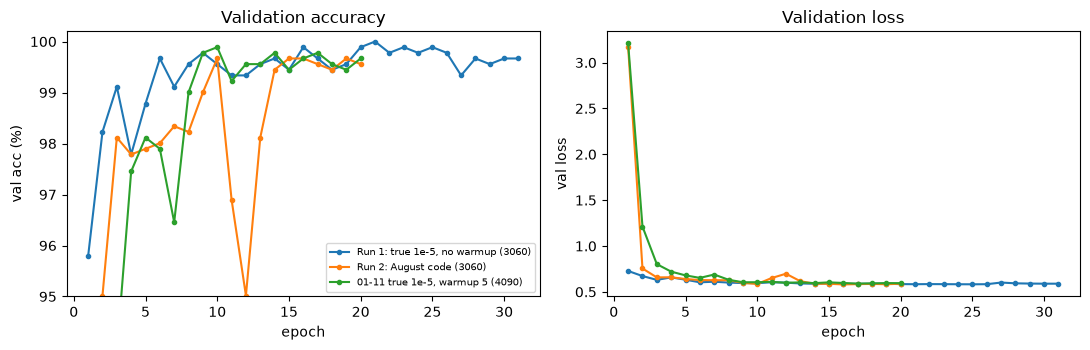

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, history in histories.items():
    frame = pd.DataFrame(history)
    axes[0].plot(frame.epoch, frame.val_acc, marker=".", label=name)
    axes[1].plot(frame.epoch, frame.val_loss, marker=".", label=name)
axes[0].set(xlabel="epoch", ylabel="val acc (%)", ylim=(95, 100.2), title="Validation accuracy")
axes[1].set(xlabel="epoch", ylabel="val loss", title="Validation loss")
axes[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(ARTIFACTS / "val_curves.png", dpi=150)
plt.show()

## Save artifacts

In [8]:
results.to_csv(ARTIFACTS / "results.csv", index=False)
saturation.to_csv(ARTIFACTS / "val_saturation.csv", index=False)
for name, rows_ in predictions.items():
    tag = name.split(":")[0].split(" (")[0].lower().replace(" ", "_")
    pd.DataFrame(rows_).to_csv(ARTIFACTS / f"predictions_test_{tag}.csv", index=False)
for source, target in [
    (RUN1_DIR / "run_config.json", "run1/run_config.json"),
    (RUN1_DIR / "history.json", "run1/history.json"),
    (RUN1_DIR / "metrics.json", "run1/metrics.json"),
    (RUN2_DIR / "run_config.json", "run2/run_config.json"),
    (RUN2_DIR / "history.json", "run2/history.json"),
    (RUN2_DIR / "param_groups.json", "run2/param_groups.json"),
    (RUN2_DIR / "test_metrics.json", "run2/test_metrics_final_epoch.json"),
    (EXP_DIR / "run1.log", "run1/train.log"),
    (EXP_DIR / "run2.log", "run2/train.log"),
]:
    (ARTIFACTS / target).parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, ARTIFACTS / target)
(ARTIFACTS / "environment.json").write_text(json.dumps(environment, indent=2))
(ARTIFACTS / "checkpoints.sha256").write_text(
    "".join(f"{r['checkpoint_sha256']}  {Path(CHECKPOINTS[r['run']]).relative_to(ROOT)}\n"
            for r in rows if r["run"] in CHECKPOINTS)
)
sorted(p.relative_to(ARTIFACTS).as_posix() for p in ARTIFACTS.rglob("*") if p.is_file())

['checkpoints.sha256',
 'environment.json',
 'predictions_test_august_original.csv',
 'predictions_test_run_1.csv',
 'predictions_test_run_2.csv',
 'results.csv',
 'run1/history.json',
 'run1/metrics.json',
 'run1/run_config.json',
 'run1/train.log',
 'run2/history.json',
 'run2/param_groups.json',
 'run2/run_config.json',
 'run2/test_metrics_final_epoch.json',
 'run2/train.log',
 'val_curves.png',
 'val_saturation.csv']